In [1]:

from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta
from scipy.optimize import least_squares
import pandas as pd
import re
import numpy as np
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

feriados = pd.read_csv('CLholidays.csv').values.tolist()
clpcam = pd.read_csv("mkt_clpcam.csv").values.tolist()
sofr = pd.read_csv("mkt_sofr.csv").values.tolist()

In [2]:
class legFixed:
    
    def __init__(self, startDate, endDate, schedule, dayCount, discount, fix):
        self.startDate = startDate
        self.endDate = endDate
        self.schedule = schedule
        self.dayCount = dayCount
        self.discount = discount
        self.fix = fix

    def __repr__(self):
        return f"legFixed(startDate={self.startDate}, endDate={self.endDate}, schedule={self.schedule}, dayCount='{self.dayCount}')"

class legFloat:
    
    def __init__(self, startDate, endDate, schedule, dayCount, discount, projection):
        self.startDate = startDate
        self.endDate = endDate
        self.schedule = schedule
        self.dayCount = dayCount
        self.discount = discount
        self.projection = projection

    def __repr__(self):
        return f"legFixed(startDate={self.startDate}, endDate={self.endDate}, schedule={self.schedule}, dayCount='{self.dayCount}')"

class oisSwap:
    
    def __init__(self, tradeDate, calendar, tenor, freq, dayCount, fix):
        self.tradeDate = tradeDate
        self.calendar = self.getCalendar(calendar)
        self.tenor = tenor
        self.freq = freq
        self.dayCount = dayCount
        self.discountFixed = []
        self.fix = fix
        self.discountFloat = []
        self.projection = []
        
        self.startDate, self.startDay = self.getStartDate(self.tradeDate, self.calendar)
        self.endDate, self.endDays = self.getEndDate(self.tenor, self.startDate, self.calendar)
        self.schedule, self.scheduleDays, self.scheduleTenorDays, self.tenorDays = self.getSchedule(self.tenor, self.endDate, self.calendar)
        self.fixedLeg = legFixed(self.startDate, self.endDate, self.schedule, self.dayCount, self.discountFixed, self.fix)
        self.floatLeg = legFloat(self.startDate, self.endDate, self.schedule, self.dayCount, self.discountFloat, self.projection)

    def getCalendar(self, calendar):
        calendarMod = []
        for i, row in enumerate(calendar):
            calendarMod.append(datetime.strptime(row[0], '%Y-%m-%d').date())
        return calendarMod
    
    def getStartDate(self, tradeDate, calendar):
        dateMod = tradeDate
        added = 0
        while (added < 2):
            dateMod += timedelta(days=1)
            if (dateMod.weekday() < 5) and (dateMod not in calendar):
                added += 1
        return dateMod, (dateMod - self.tradeDate).days
    
    def getAdjust(self, date, calendar):
            dateMod = date
            while not (dateMod.weekday() < 5) or (dateMod in calendar):
                dateMod += timedelta(days=1)
            if dateMod.month != date.month:
                dateMod = date
                while not (dateMod.weekday() < 5) or (dateMod in calendar):
                    dateMod -= timedelta(days=1)
            return dateMod
        
    def getEndDate(self, tenor, startDate, calendar):
        if 'D' in tenor:
            days = int(tenor.replace('D', ''))
            unadjustedEndDate = startDate + relativedelta(days=days)
        if 'W' in tenor:
            weeks = int(tenor.replace('W', ''))
            unadjustedEndDate = startDate + relativedelta(weeks=weeks)
        elif 'M' in tenor:
            months = int(tenor.replace('M', ''))
            unadjustedEndDate = startDate + relativedelta(months=months)
        elif 'Y' in tenor:
            years = int(tenor.replace('Y', ''))
            unadjustedEndDate = startDate + relativedelta(years=years)
        dateMod = self.getAdjust(unadjustedEndDate, calendar)
        return dateMod, (dateMod - self.tradeDate).days
    
    def gedDaysBetween(self, date1, date2):
        return (date2 - date1).days
        
    def getSchedule(self, tenor, endDate, calendar):
        scheduleMod = []
        scheduleDays = []
        scheduleTenorDays = []
        tenorDays = []
        if self.freq == 'zero':
            scheduleMod.append(self.getAdjust(endDate, calendar))

            # TODO SIEMPRE desde startDate (T+2)
            if tenor == "0D":
                scheduleDays.append(self.gedDaysBetween(self.tradeDate, endDate))
                scheduleTenorDays.append(self.gedDaysBetween(self.tradeDate, endDate))
                tenorDays.append(self.gedDaysBetween(self.startDate, endDate))
            else:
                scheduleDays.append(self.gedDaysBetween(self.tradeDate, endDate))
                scheduleTenorDays.append(self.gedDaysBetween(self.startDate, endDate))
                tenorDays.append(self.gedDaysBetween(self.startDate, endDate))
            


        elif self.freq == 'semiannual':
            cashflows = int(tenor.replace('Y', ''))* 2
            
            for i in range(1, cashflows + 1):
                unadjustedDate = self.startDate + relativedelta(months=6) * i
                adjustedDate = self.getAdjust(unadjustedDate, calendar)
                scheduleMod.append(adjustedDate)
                if i == 1:
                    scheduleDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
                    scheduleTenorDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
                else:
                    scheduleDays.append(self.gedDaysBetween(scheduleMod[i-2], scheduleMod[i-1]))
                    scheduleTenorDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
            tenorDays.append(self.gedDaysBetween(self.startDate, endDate))
         
        return scheduleMod, scheduleDays, scheduleTenorDays, tenorDays
    
    def daycount(self):
        """
        Devuelve el factor de daycount para accrual.
        """
        if self.dayCount.lower() == "act/360":
            return 1.0 / 360.0
        elif self.dayCount.lower() == "act/365":
            return 1.0 / 365.0
        else:
            raise ValueError(f"Unsupported day count: {self.dayCount}")



    def __repr__(self):
        return f"oisSwap(tradeDate={self.tradeDate}, tenor={self.tenor}, freq='{self.freq}', dayCount='{self.dayCount}')"

In [3]:
tradeDate = datetime.strptime(clpcam[0][3][:10], '%Y-%m-%d').date()
inst = {}
SCHEDULEDAYS = []
SCHEDULETENOR = []
SCHEDULE = []
for i, row in enumerate(clpcam):    
    if i == 0:
        oisswap = oisSwap(tradeDate, feriados, '0D', 'zero', 'act/360', row[2])
    else:
        tenor = re.split(r'(?<=\d)(?=[A-Za-z])', row[1])
        if ('Y' in tenor[1]) and (int(tenor[0]) >= 2):
            oisswap = oisSwap(tradeDate, feriados, row[1], 'semiannual', 'act/360', row[2])
        else:
            oisswap = oisSwap(tradeDate, feriados, row[1], 'zero', 'act/360', row[2])
    inst[oisswap.tenor] = oisswap
    startDate = oisswap.startDate
    SCHEDULEDAYS.append(oisswap.scheduleDays)
    SCHEDULETENOR.append(oisswap.scheduleTenorDays)
    SCHEDULE.append(oisswap.schedule)



In [4]:
class curve:
    def __init__(self, inst, discount=None, projection=None, interpolator=None):
        self.inst = inst
        self.pillar, self.pillarDays, self.pillarTenorDays, self.tenorDays = self.getPillars()
        self.market = self.getPar()
        # daycount (factor) lo tomas desde UN swap (todos OIS con misma convención)
        swap0 = next(iter(self.inst.values()))
        self.dc = swap0.daycount()
        self.discount = discount if discount is not None else []
        self.projection = projection if projection is not None else []
        self.interpolator = self.linearInterpolate if interpolator is None else interpolator 
    
    def getPillars(self):
        """
        Construye una grilla de pilares CONSISTENTE.

        - pillarTenorDays: días acumulados desde startDate (t) para cada cashflow, únicos y ordenados.
        - pillarDays: delta entre pilares (t_k - t_{k-1}), con t_0 - 0.
        - pillar: fechas asociadas (ordenadas por t).
        - tenorDays: madurez por instrumento (para alinear con market).
        """

        # 1) Recolecta todos los cashflows (t en días desde startDate) + su fecha
        t_to_date = {}  # t(int) -> date
        for key in self.inst:
            sw = self.inst[key]
            for t, dt in zip(sw.scheduleTenorDays, sw.schedule):
                t = int(t)
                # si hay duplicados, nos quedamos con la primera fecha (deberían coincidir)
                if t not in t_to_date:
                    t_to_date[t] = dt

        # 2) Ordena por tenor day
        pillarTenorDays = sorted(t_to_date.keys())
        pillarDates = [tradeDate] + [t_to_date[t] for t in pillarTenorDays]

        # 3) pillarDays = deltas entre pilares (en días)
        pillarDays = []
        prev = 0
        for t in pillarTenorDays:
            pillarDays.append(int(t - prev))
            prev = t

        # 4) tenorDays por instrumento (madurez final por instrumento)
        # (para que market y tenorDays queden alineados, ordenar por madurez)
        inst_sorted = sorted(self.inst.values(), key=lambda sw: int(sw.tenorDays[0]))
        tenorDays = [(startDate - tradeDate).days]+[int(sw.tenorDays[0]) for sw in inst_sorted]
        del tenorDays[1]
        tenorDays = [0] + tenorDays
        pillarTenorDays = tenorDays.copy()

        # guarda en self y retorna
        self.pillar = pillarDates
        self.pillarDays = pillarDays
        self.pillarTenorDays = pillarTenorDays
        self.tenorDays = tenorDays
        

        return self.pillar, self.pillarDays, self.pillarTenorDays, self.tenorDays

    
    def getPar(self):
        inst_sorted = sorted(self.inst.values(), key=lambda sw: int(sw.tenorDays[0]))
        self.market = np.asarray([float(sw.fix) for sw in inst_sorted], dtype=float).reshape(-1)
        return self.market

    
    def linearIntepolator(self, x0, x1, y0, y1, x):
        y = y0 + (y1 - y0) * (x - x0) / (x1 - x0)
        return y
    
    def linearInterpolate(self, tenorDays, pillarTenorDays):
        if len(self.discount) != len(tenorDays):
            raise ValueError("discount and tenorDays must match")

        xs = np.asarray(tenorDays, float) / self.dc
        dfs = np.asarray(self.discount, float)
        if np.any(dfs <= 0):
            raise ValueError("DF must be > 0")

        # zero continuo en %: z = -ln(DF)/t
        z = np.zeros_like(xs)
        z[0] = -np.log(dfs[0]) / max(xs[0], 1e-12)
        for i in range(1, len(xs)):
            z[i] = -np.log(dfs[i]) / xs[i]

        # interpolar z lineal en tiempo
        out = []
        for d in pillarTenorDays:
            t = float(d) / self.dc
            if t <= xs[0]:
                zt = z[0]
            elif t >= xs[-1]:
                zt = z[-1]
            else:
                zt = float(np.interp(t, xs, z))
            out.append(float(np.exp(-zt * t)))
        return out
    def loglinearInterpolateDF(self, tenorDays, pillarTenorDays):
        """
        Interpolación log-lineal en DF:
        lineal en log(DF) ⇔ lineal en zero rates continuos.
        """

        if len(self.discount) != len(tenorDays):
            raise ValueError(
                f"Discount curve not initialized: "
                f"len(discount)={len(self.discount)} != len(tenorDays)={len(tenorDays)}"
            )

        xs = np.asarray(tenorDays, dtype=float)
        dfs = np.asarray(self.discount, dtype=float)

        if np.any(dfs <= 0):
            raise ValueError("All discount factors must be > 0.")

        log_dfs = np.log(dfs)

        out = []
        for d in pillarTenorDays:
            d = float(d)

            if d <= xs[0]:
                out.append(float(dfs[0]))
            elif d >= xs[-1]:
                out.append(float(dfs[-1]))
            else:
                out.append(float(np.exp(np.interp(d, xs, log_dfs))))

        return out


    def getForward(self):
        if not self.discount:
            raise ValueError("self.discount is empty. Bootstrap DF first.")

        df_p = self.loglinearInterpolateDF(self.tenorDays, self.pillarTenorDays)

        self.projection = [np.nan]
        for k in range(1, len(self.pillarTenorDays)):
            d0 = float(self.pillarTenorDays[k-1])
            d1 = float(self.pillarTenorDays[k])
            # usamos la convención del OIS (todos usan la misma)
            swap0 = next(iter(self.inst.values()))
            dc = swap0.daycount()
            tau = (d1 - d0) * dc

            fwd = -np.log(df_p[k] / df_p[k-1]) / tau
            self.projection.append(float(fwd))

        return self.projection


    def getProjection(self):
        f = self.projection.copy()
        f = np.asarray(f, dtype=float).reshape(-1)
        proj = f
        return proj
    def CashFlows(self):
        cfs = (self.market - self.getProjection())*self.linearInterpolate(self.discount,self.tenorDays,self.pillarTenorDays)*self.pillarDays*self.dayCount
        PV = np.sum(cfs)
        return PV
    #interes continuo act/360
    #interp lineal

cam = curve(inst)


In [5]:
class iterativeCalibrator:
    def __init__(self, curve):
        self.curve = curve

        # Copias "inmutables" locales (no dependas de que curve se mutee después)
        self.market = curve.market.copy()
        self.tenorDays = curve.tenorDays.copy()                 
        self.pillarTenorDays = curve.pillarTenorDays.copy()     
        self.pillarDays = curve.pillarDays.copy()
        self.dc = curve.dc

        # 1) Interpola market a la malla de pilares 
        self.pillarMarket = self.linearInterpolate(self.tenorDays, self.pillarTenorDays, self.market)

        # 2) Construye DF por pilar (día -> DF) SIN deduplicar por valor
        self.df_by_day = {}
        for d, r in zip(self.pillarTenorDays, self.pillarMarket):
            # tu fórmula actual (ojo: asume "zero cc", pero lo mantenemos)
            df = np.exp(-(r/100.0) * d * (1/360.0))
            self.df_by_day[d] = float(df)

        # 3) Publica curva de descuento en la MISMA malla que pillarTenorDays
        self.curve.tenorDays = self.pillarTenorDays
        self.curve.discount  = [self.df_by_day[d] for d in self.pillarTenorDays]

    def linearIntepolator(self, x0, x1, y0, y1, x):
        return y0 + (y1 - y0) * (x - x0) / (x1 - x0)

    def linearInterpolate(self, tenorDays, pillarTenorDays, market):
        # tenorDays y market: 22
        # pillarTenorDays: 65
        rate = []
        for day in pillarTenorDays:
            if day in tenorDays:
                j = tenorDays.index(day)
                rate.append(float(market[j-1]))
                continue

            for j in range(1, len(tenorDays)):
                if pillarTenorDays[j] > day:
                    x0, x1 = pillarTenorDays[j-1], pillarTenorDays[j]
                    y0, y1 = float(market[j-1]), float(market[j])
                    rate.append(self.linearIntepolator(x0, x1, y0, y1, day))
                    break
            else:
                rate.append(float(market[-1]))
        return rate

calibrator = iterativeCalibrator(cam)




In [6]:

class solver:
    def __init__(self, curve, calibrator=None):
        self.curve = curve
        self.calibrator = calibrator

        self.dc = curve.dc

        # instrumentos ordenados por madurez
        self.inst_sorted = sorted(curve.inst.values(), key=lambda sw: int(sw.scheduleTenorDays[-1]))
        # malla de mercado y rates de mercado *desde los swaps*
        inst_mkt = [sw for sw in self.inst_sorted]
          
        self.market = np.asarray([float(sw.fix) for sw in inst_mkt], dtype=float)                 # 22
        
        # pilares
        self.pillarTenorDays = np.asarray(cam.pillarTenorDays, dtype=float)
        self.tenorDays_mkt = self.pillarTenorDays
        self.initial_guess = self.market.copy()
        self.initial_guess = np.concatenate([[cam.market[0]],self.initial_guess])
        self.initial_guess = np.tile(self.initial_guess,2)

    def objective_function(self, zeros):

        zeros = np.asarray(zeros, dtype=float)  
       
        indx = 0
        Error = []
        error = 0.0
        
       
        
        for sw in self.inst_sorted[0:23]:
            
            
            
            zeros_d = zeros[:23]
            zeros_p = zeros[23:]
            R = float(sw.fix/100)
            
            times = np.asarray(sw.scheduleTenorDays, dtype=float)
            t_mkt_years = np.asarray(cam.pillarTenorDays,dtype=float) * self.dc # días
            
            # DF curva descuento en malla de mercado 
            DF_mkt = np.exp(-(zeros_d / 100.0) * t_mkt_years)
            # DF curva proyección en malla de mercado 
            DF_mkt2 = np.exp(-(zeros_p / 100.0) * t_mkt_years)
            # log-linear DF helper: DF(t) para cualquier t en días
            logDF = np.log(DF_mkt)
            logDF2 = np.log(DF_mkt2)
            T = list(range(cam.pillarTenorDays[-1]+1))                
            T = np.asarray(T,dtype=float)
            def df_at(times_days,df):
                return np.exp(UnivariateSpline(cam.pillarTenorDays,df,k=3,s=0)(times_days))
            
            
            dfs = np.array(df_at(times,logDF))
            
           
            
        
            dfsinter = list(df_at(T,logDF2))
            
            
            

            # accruals por periodo (años)
            accruals = []
            for i,item in enumerate(sw.scheduleTenorDays):
                accruals.append((sw.scheduleTenorDays[i] - sw.scheduleTenorDays[i-1])*self.dc)
                accruals[0] = (sw.scheduleTenorDays[0])*self.dc
            accruals = np.asarray(accruals,dtype=float)
            accruals2 = np.diff(np.concatenate([[float((startDate - tradeDate).days)], times])) * self.dc
            
            
            
      
            Ffil = []
           
        
            if indx == 0:
                fwd = -(1 - dfsinter[0]/dfsinter[cam.pillarTenorDays[1]])/(cam.pillarTenorDays[1]*self.dc)
                Ffil.append(fwd)
            else:
                for k,day in enumerate(sw.scheduleTenorDays):
                    
                    if k == 0:
                        fwd = -(1 - dfsinter[cam.pillarTenorDays[1]]/dfsinter[sw.scheduleTenorDays[k]])/accruals2[k]
                    elif k >= 1:
                        fwd = -(1 - dfsinter[sw.scheduleTenorDays[k-1]]/dfsinter[sw.scheduleTenorDays[k]])/accruals2[k]
                    Ffil.append(fwd)
           
            
     
            Ffil = np.asarray(Ffil,dtype=float)
            
            
            
            PV = (dfs*accruals * (np.full(len(Ffil),R) - (Ffil)))**2
            
            error = np.sum(PV)
            Error.append(error)  
            indx += 1      
        self.Flot = [i*100 for i in Ffil]
        self.dfsinter = dfsinter
        self.dfs = dfs
        self.accruals2 = accruals2
        self.accruals = accruals
        return np.asarray(Error,dtype=float)

       


    def solve(self):
        bl = 0.9*self.initial_guess
        bh = 1.1*self.initial_guess
        
        bounds = (bl,bh)

        res = least_squares(
            self.objective_function,
            x0=self.initial_guess,
            bounds=bounds,
            ftol=1e-06,
            xtol=8e-04,
            gtol=None,
            max_nfev=200
            
        )

        if not res.success:
            raise RuntimeError(res.message)

        return res.x

   

   


In [7]:
ss = solver(cam, calibrator)
ss.initial_guess

array([4.75 , 4.75 , 4.72 , 4.665, 4.61 , 4.525, 4.47 , 4.445, 4.46 ,
       4.49 , 4.575, 4.67 , 4.76 , 4.845, 4.925, 4.995, 5.055, 5.115,
       5.205, 5.29 , 5.345, 5.37 , 5.38 , 4.75 , 4.75 , 4.72 , 4.665,
       4.61 , 4.525, 4.47 , 4.445, 4.46 , 4.49 , 4.575, 4.67 , 4.76 ,
       4.845, 4.925, 4.995, 5.055, 5.115, 5.205, 5.29 , 5.345, 5.37 ,
       5.38 ])

In [8]:

x = ss.solve()



In [9]:

print(x[:23])
print(ss.initial_guess[:23])

[4.75       4.75       4.71999999 4.66500007 4.60999983 4.52508944
 4.46999646 4.44527002 4.46022607 4.490372   4.57533815 4.67011788
 4.76008438 4.84512906 4.92522926 4.99533023 5.05532624 5.11562958
 5.2058173  5.29056065 5.34518978 5.37004492 5.3800049 ]
[4.75  4.75  4.72  4.665 4.61  4.525 4.47  4.445 4.46  4.49  4.575 4.67
 4.76  4.845 4.925 4.995 5.055 5.115 5.205 5.29  5.345 5.37  5.38 ]


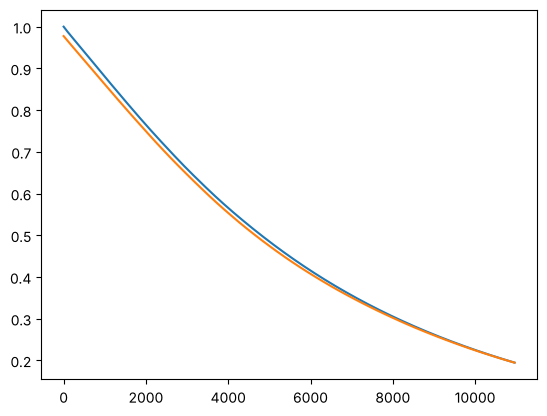

In [10]:
plt.plot(range(cam.pillarTenorDays[-1]+1),ss.dfsinter)
rango = np.linspace(0,cam.pillarTenorDays[-1],len(ss.dfs))
plt.plot(rango,ss.dfs)


In [11]:
ss.objective_function(x)


array([3.29358782e-16, 3.52960030e-11, 6.35222381e-10, 3.88906414e-09,
       4.69388714e-08, 2.90787438e-07, 1.23064671e-06, 5.45148149e-06,
       1.40208493e-06, 4.52507631e-06, 8.49234424e-06, 1.42178450e-05,
       2.01494948e-05, 2.60867907e-05, 3.35394816e-05, 3.96468582e-05,
       4.68488997e-05, 5.76970627e-05, 7.06939911e-05, 8.12167976e-05,
       8.57303519e-05, 8.74569254e-05])

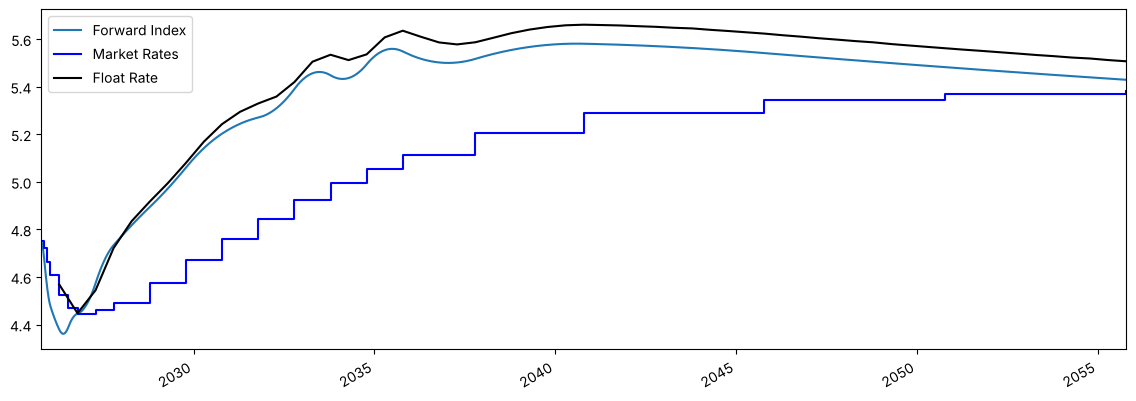

In [12]:

def objective_function2(self, zeros):

        zeros = np.asarray(zeros, dtype=float) 
       
        indx = 0
        Error = []
        error = 0.0
        
        dfsinter2=[]
        savedLenght = 0
        Ffin = []
        plt.figure(figsize=(14,5))
        for sw in self.inst_sorted[0:23]: 
            
            
            zeros_d = zeros[:23]
            zeros_p = zeros[23:]
            R = float(sw.fix/100)
            times = np.asarray(sw.scheduleTenorDays, dtype=float)
            t_mkt_years = np.asarray(cam.pillarTenorDays,dtype=float) * self.dc # días
            
            # DF curva descuento en malla de mercado (22)
            DF_mkt = np.exp(-(zeros_d / 100.0) * t_mkt_years)
            # DF curva proyección en malla de mercado (22)
            DF_mkt2 = np.exp(-(zeros_p / 100.0) * t_mkt_years)
            # log-linear DF helper: DF(t) para cualquier t en días
            logDF = np.log(DF_mkt)
            logDF2 = np.log(DF_mkt2)
            T = list(range(cam.pillarTenorDays[-1]+1))                
            T = np.asarray(T,dtype=float)
            def df_at(times_days,df):
                return np.exp(UnivariateSpline(cam.pillarTenorDays,df,k=3,s=0)(times_days))
            
            
            dfs = np.array(df_at(times,logDF))
            
            
            dfsinter = list(df_at(T,logDF2))
            
            dfsinter2 += dfsinter[savedLenght:]
            
                
            
            

            # accruals por periodo (años)
            
            accruals3 = np.diff(np.concatenate([[-1.0], T])) * self.dc
            
            
            F = [] 
            Ffil = []
            if indx == 0:
                for k in range(sw.scheduleTenorDays[0]):
                    fwd = 100*np.log(dfsinter[k]/dfsinter[k+1])/(accruals3[k+1])
                    Ffil.append(fwd)
            else:
                for k in range(sw.scheduleTenorDays[0],sw.scheduleTenorDays[-1]+1):
                    
                    fwd = 100*np.log(dfsinter[k-1]/dfsinter[k])/accruals3[k]
                    Ffil.append(fwd)
                    Ffin.append(fwd)

            
            for k in range(1,len(T)):   
                F.append(-100*(np.log(dfsinter[k])-np.log(dfsinter[k-1])) / accruals3[k])
            
            Ffil = np.asarray(Ffil,dtype=float)
            indx += 1     
            
            plt.plot(list(sw.scheduleTenorDays),ss.Flot[:len(sw.scheduleTenorDays)],color='k')
            
            
        
        # Usamos dates_f (ajustando el largo si es necesario)
        base_date = datetime.combine(tradeDate, datetime.min.time())
        dates_f = [base_date + timedelta(days=int(d)) for d in T]
        dates_pillars = [base_date + timedelta(days=int(d)) for d in cam.pillarTenorDays]
        

        plt.plot(dates_f[1:], F, label="Forward Index") 

        # Usamos dates_pillars
        plt.step(dates_pillars, ss.initial_guess[:23], where='post', label='Market Rates', color='blue')

        # Debes convertir sw.scheduleTenorDays a fechas también
        dates_sw = [base_date + timedelta(days=int(d)) for d in sw.scheduleTenorDays]
        plt.plot(dates_sw, ss.Flot[:len(sw.scheduleTenorDays)], label='Float Rate', color='k')
        
            
        Ffin = np.asarray(Ffin,dtype=float)
        
         

        # Establecer el límite izquierdo
        plt.gca().set_xlim(left=base_date, right=base_date + timedelta(days=int(T[-1])))

        # Formatear para ver el año cada 5 años
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        plt.gca().xaxis.set_major_locator(mdates.YearLocator(5))

        # Opcional: Rotar las etiquetas para que no se solapen
        plt.gcf().autofmt_xdate() 
        plt.legend()
        plt.show()
        
       
objective_function2(ss,x)


In [13]:
import numpy as np

def bootstrap_ois(cam):
    # Ordena instrumentos por madurez (en días desde startDate)
    swaps = sorted(
    [sw for sw in cam.inst.values()],
    key=lambda sw: sw.tenorDays[0]
)


    DF_by_day = {0:1}  # día 0 (startDate) tiene DF=1
    df_nodes = []
    day_nodes = []

    for k,sw in enumerate(swaps):
        R = float(sw.fix) / 100.0  # % -> decimal

        pay_days = list(sw.scheduleTenorDays)     # días desde startDate
        accr = np.array(sw.scheduleDays, float) * sw.daycount()

        # suma de cupones (menos el último)
        S = 0.0
        for d, a in zip(pay_days[:-1], accr[:-1]):
            # interp lineal si el cupón no coincide con un nodo exacto
            if d in DF_by_day:
                df_d = DF_by_day[d]
            else:
                ks = np.array(sorted(DF_by_day.keys()), float)
                vs = np.array([DF_by_day[k] for k in ks], float)
                df_d = np.interp(d, ks, vs)
            S += a * df_d

        a_last = float(accr[-1])
        T = pay_days[-1]

        # ecuación par OIS: R*(S + a_last*DF(T)) = 1 - DF(T)
        # => DF(T) = (1 - R*S) / (1 + R*a_last)
        if k==0: 
            dft0 = (1.0 - R * S) / (1.0 + R * a_last)
            DF_T = dft0
        else:
            DF_T = (dft0 - R * S) / (1.0 + R * a_last)

        DF_by_day[T] = DF_T
        day_nodes.append(T)
        df_nodes.append(DF_T)

    # deja la curva de descuento definida en los nodos de instrumentos (o puedes usar pilares)
    cam.discount  = df_nodes
    if cam.tenorDays[0] == 0:
        cam.tenorDays = cam.tenorDays
        cam.discount[0] = dft0
        cam.discount = [1] + cam.discount 
    items = list(DF_by_day.items())
    items[1] = (items[1][0], dft0)
    

    it = iter(DF_by_day.items())
    primer_tag, primer_valor = next(it)

    # Reconstruimos: el nuevo primero + el resto
    DF_by_day = {(startDate - tradeDate).days: primer_valor, **dict(it)}
    return DF_by_day



In [14]:

cam = curve(inst)
DFmap = bootstrap_ois(cam)
fw = cam.getForward()


print(DFmap)

{2: 0.9997361807300852, 31: 0.9954292900020099, 61: 0.9916406741762785, 94: 0.9875953419925239, 182: 0.9771371694173928, 273: 0.9667264988223794, 367: 0.9561717983810946, 549: 0.9358523029415636, 731: np.float64(0.9135137907068255), 1096: np.float64(0.8705079549451542), 1461: np.float64(0.8281197269502137), 1826: np.float64(0.7863653102704983), 2191: np.float64(0.7454443592295278), 2558: np.float64(0.7053254713551781), 2922: np.float64(0.6670052811804227), 3287: np.float64(0.6302570473633579), 3652: np.float64(0.5945874373264209), 4385: np.float64(0.5267277198938045), 5479: np.float64(0.43939984038075297), 7305: np.float64(0.3234988931021944), 9131: np.float64(0.2484582219949912), 10958: np.float64(0.19003216365758085)}


In [15]:


def build_df_interpolator_loglinear(DFmap):
    xs = np.array(sorted(DFmap.keys()), dtype=int)
    ys = np.log(np.array([DFmap[k] for k in xs], dtype=float))
    T = list(range(0,xs[-1]+1))
    T = np.asarray(T,dtype=float)
    def df(t):
    
        return np.exp(np.interp(t, xs, ys))
    DFinter = df(T)
    return DFinter, T

def forwards_from_DFmap_interp(DFmap, tenorDays, dc):
    if 0 not in DFmap:
        DFmap[0] = 1.0
    df, T = build_df_interpolator_loglinear(DFmap)
    
    fw = [np.nan]
  
    tau = np.diff(np.concatenate([[-1.0], T])) * dc
    for k,i in zip(range(tenorDays[-1]), range(1,tenorDays[-1]+1)):
        DF0 = df
        DF1 = df
        
        fw.append(-np.log(DF1[i]/DF0[k]) / tau[k])
        
    
    print(f"Dias: {tenorDays[1]} a {tenorDays[2]}, DF0: {df[tenorDays[1]]}, DF1: {df[tenorDays[2]]}, Tau: {(tenorDays[2]-tenorDays[1])*dc}")
    return fw, T


fw_boot, T = forwards_from_DFmap_interp(DFmap, cam.tenorDays, cam.dc)

print(fw_boot)




Dias: 2 a 31, DF0: 0.9997361807300852, DF1: 0.9954292900020099, Tau: 0.08055555555555556
[nan, np.float64(0.047493733741240204), np.float64(0.047493733741240204), np.float64(0.05359448551780738), np.float64(0.0535944855177674), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.0535944855177674), np.float64(0.05359448551780738), np.float64(0.0535944855177674), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.0535944855177674), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.05359448551784735), np.float64(0.0535944855177674), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.05359448551780738), np.float64(0.0535

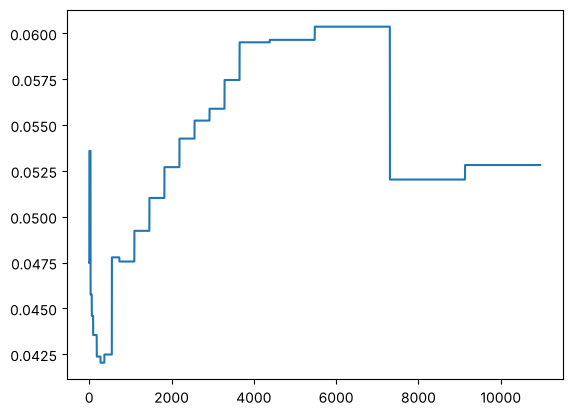

In [16]:
plt.plot(T,fw_boot)